# Problem Set 1
### Cheaper food, better nutrition? Evaluating a staple-food subsidy
#### Group: Jose Eduardo Campos Hernandez, Drishti Khemlani, Madeleine Roberts

##### Data import and cleaning

In [ ]:
# Import packages
library(tidyverse)
library(gt)
library(fixest)

# Import data
staple_households <- read_csv("staple_households.csv", show_col_types = FALSE)
food_energy <- read_csv("food_energy.csv", show_col_types = FALSE)

raw_data <- staple_households |>
  pivot_longer(
    cols          = matches("_(g|price_kg)$"),
    names_to      = c("food", ".value"),
    names_pattern = "(.*)_(g|price_kg)$"
  ) |>
  left_join(food_energy, by = "food") |>
  transmute(
    household_id, region, treated, wave,
    baseline_resources, cash_resources,
    food_spending, other_spending, subsidy_cost,
    food,
    price_g             = price_kg / 1000,
    kcal_per_g,
    grams_consumed      = g,
    food_caloric_intake = grams_consumed * kcal_per_g,
    food_share_spending = grams_consumed * price_g / food_spending * 100
  )

raw_data[sample(nrow(raw_data), 5), ]

household_id,region,treated,wave,baseline_resources,cash_resources,food_spending,other_spending,subsidy_cost,food,price_g,kcal_per_g,grams_consumed,food_caloric_intake,food_share_spending
<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
H227,A,1,During,9.47,9.57,2.8579,6.7121,0.21804,rice,0.0018,3.6,363.4,1308.24,22.888135
H205,A,1,Before,7.09,7.09,2.7739,4.3161,0.00000,oil,0.0100,9.0,20.1,180.90,7.246116
H443,B,1,During,7.27,7.37,2.4341,4.9359,0.27858,vegetables,0.0020,0.3,258.9,77.67,21.272750
H240,A,1,Before,11.19,11.19,2.8543,8.3357,0.00000,rice,0.0024,3.6,555.8,2000.88,46.733700
H195,A,0,Before,8.10,8.10,2.5618,5.5382,0.00000,fish,0.0120,1.2,62.3,74.76,29.182606


##### **Question 1: Understand the data and make a prediction**
*Before calculating policy effects, record your prediction about how households will respond to cheaper rice and whether calorie intake will increase. State the reasoning and assumptions behind your prediction.*

[MR comment]: we could start with a basic prediction like this one

We predict that households will respond to cheaper rice by consuming more rice, therefore for their calorie intake to increase. We assume a downward-sloping demand curve where the Q demanded of rice increases as price of rice decreases. More rice consumed will result in more calorie intake.

[MR comment]: or add a few caveats
1. Substitution effect: rice is now relatively cheaper, which pushes rice consumption up.
2. Income effect: rice takes a large share of the budget, so a 25% cut frees up real money. Whether that money pushes rice up or down depends on whether rice is a normal or inferior good for these households.
Calories ≠ rice: even if rice rises, the freed money can move into fish or oil (oil is very calorie-dense at 9 kcal/g), vegetables, or non-food spending.

[JE] Rice is the staple food in this sample: it provides the cheapest source of calories and forms the base of household diets, much as potatoes or maize tortillas do in other contexts. More expensive foods, such as fish, add taste and variety. This structure shapes our prediction. If households already cover a basic calorie need with rice and value variety, a lower rice price frees resources that they may spend on preferred foods rather than on additional rice. Whether rice consumption responds to income is an empirical question that the baseline data allow us to examine.

 *Explore and audit the dataset. What do you need to check before trusting an analysis of this pilot? Give a concise account of the sample, the policy as implemented and any data issues. Construct a measure of the policy’s stated outcome, explaining its units and any transformations you make.*

The sample follows 480 households in two regions: 240 for both A and B regions, with 50% as control group and 50% as treatment group in both. The data is captured in three different waves in time (before, during and after treatment). Our checks show that there is no survey attrition, no missing values and exactly one row per household per wave. Treatment and region stay the same for each household across waves. Unit of observation: household × wave, N = 1,440 (480 households × 3 waves). Randomisation is at household level within region.

Before trusting an analysis of this pilot we need to validate the randomisation by testing, in the before wave, whether households who received the subsidy and households who didn't receive the subsidy are balanced across baseline characteristics relevant to our outcome (calorie intake).

Table 1 provides means for treatment and control groups for key variables in the baseline survey and the differences of means. Overall, none of the differences is statistically significant. Splitting the sample by region confirms this result.

In [74]:
labels <- c(baseline_resources   = "Baseline resources (per person/day)",
            food_spending        = "Food spending (per person/day)",
            other_spending       = "Other spending (per person/day)",
            rice_share           = "Share of food spending on rice (%)",
            total_caloric_intake = "Calorie intake (kcal/person/day)",
            kcal_rice            = "  Rice (kcal)",
            kcal_fish            = "  Fish (kcal)",
            kcal_vegetables      = "  Vegetables (kcal)",
            kcal_oil             = "  Oil (kcal)")

# One row per household in the Before wave
food_kcal <- raw_data |>
  filter(wave == "Before") |>
  select(household_id, food, food_caloric_intake) |>
  pivot_wider(names_from = food, values_from = food_caloric_intake, names_prefix = "kcal_")

check_data <- raw_data |>
  filter(wave == "Before", food == "rice") |>
  select(household_id, region, treated, baseline_resources, food_spending, other_spending,
         rice_share = food_share_spending) |>
  left_join(food_kcal, by = "household_id") |>
  mutate(total_caloric_intake = kcal_rice + kcal_fish + kcal_vegetables + kcal_oil)

# Stack the full sample and each region, then test every variable in one pass
balance <- bind_rows(check_data |> mutate(sample = "Total"),
                     check_data |> mutate(sample = paste("Region", region))) |>
  select(sample, treated, all_of(names(labels))) |>
  pivot_longer(-c(sample, treated)) |>
  group_by(sample, name) |>
  summarise(Treatment  = mean(value[treated == 1]),
            Comparison = mean(value[treated == 0]),
            p_value    = t.test(value[treated == 1], value[treated == 0])$p.value,
            .groups = "drop") |>
  mutate(stars      = case_when(p_value < 0.01 ~ "***",
                                p_value < 0.05 ~ "**",
                                p_value < 0.10 ~ "*",
                                TRUE           ~ ""),
         Difference = paste0(sprintf("%.2f", Treatment - Comparison), stars),
         Variable   = factor(labels[name], levels = labels))

balance_wide <- balance |>
  select(sample, Variable, Treatment, Comparison, Difference) |>
  pivot_wider(names_from  = sample,
              values_from = c(Treatment, Comparison, Difference),
              names_glue  = "{sample}|{.value}") |>
  arrange(Variable) |>
  select(Variable, starts_with("Total"), starts_with("Region A"), starts_with("Region B"))

tbl1 <- balance_wide |>
  gt(rowname_col = "Variable") |>
  tab_header(title = "Table 1: Covariate balance in the Before wave") |>
  tab_spanner_delim(delim = "|") |>
  fmt_number(columns = matches("Treatment|Comparison"), decimals = 2) |>
  cols_align(align = "center") |>
  tab_style(style = list(cell_fill(color = "grey85"), cell_text(weight = "bold")),
            locations = cells_column_spanners()) |>
  opt_row_striping() |>
  tab_source_note("Means in the Before wave. Difference = Treatment − Comparison; stars from Welch two-sample t-tests: * p < 0.10, ** p < 0.05, *** p < 0.01. N = 240 households per group in Total; 120 per group in each region.")

IRdisplay::display_html(as_raw_html(tbl1))

"Means in the Before wave. Difference = Treatment − Comparison; stars from Welch two-sample t-tests: * p < 0.10, ** p < 0.05, *** p < 0.01. N = 240 households per group in Total; 120 per group in each region."


The outcome is household calorie intake as measured by kcal per person per day, calculated as 3.6·rice_g + 1.2·fish_g + 0.3·veg_g + 9·oil_g

## Question 2: Explore the data
*Before evaluating the policy, explore the main features of the data. Choose a small set of descriptive tables and figures that help you understand households’ consumption, resources and spending, and how these vary across the sample and over time. Describe the patterns you find most informative or surprising. What questions do they raise? How should these patterns inform your subsequent policy evaluation? Explain why you selected each table or figure.*

Cash resources could confound the estimated effect only if they changed differently for treated and control households. Figure 1 shows mean cash resources, without the subsidy, by group, wave and region. Two patterns stand out. First, cash resources rise in the During wave and return to their initial level in the After wave, but this movement is common to treated and control households in both regions. Second, in region B treated households hold slightly more cash than control households in every wave; this gap is constant over time and is not statistically significant at baseline (Table 1). Neither pattern threatens the evaluation: the comparison with control households absorbs changes common to both groups, and household fixed effects absorb constant differences between them. Cash resources therefore do not explain the fall in calorie intake among treated households.

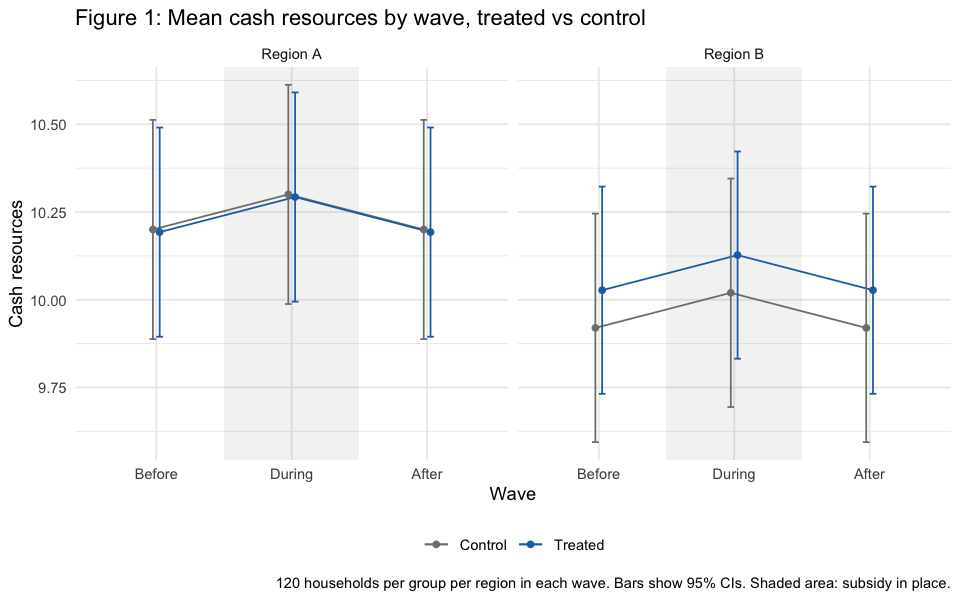

In [77]:
dodge <- position_dodge(0.1)

options(repr.plot.width = 8, repr.plot.height = 5)

raw_data |>
  filter(food == "rice") |>
  mutate(wave  = factor(wave, levels = c("Before", "During", "After")),
         group = if_else(treated == 1, "Treated", "Control"),
         region = paste("Region", region)) |>
  group_by(region, wave, group) |>
  summarise(mean = mean(cash_resources),
            se = sd(cash_resources) / sqrt(n()),
            .groups = "drop") |>
  ggplot(aes(wave, mean, colour = group, group = group)) +
  annotate("rect", xmin = 1.5, xmax = 2.5, ymin = -Inf, ymax = Inf, alpha = 0.08) +
  geom_line(position = dodge) +
  geom_point(position = dodge) +
  geom_errorbar(aes(ymin = mean - 1.96 * se, ymax = mean + 1.96 * se),
                width = 0.1, position = dodge) +
  facet_wrap(~ region) +
  scale_colour_manual(values = c(Control = "grey50", Treated = "#1f6fb4")) +
  labs(title = "Figure 1: Mean cash resources by wave, treated vs control",
       x = "Wave", y = "Cash resources", colour = NULL,
       caption = "120 households per group per region in each wave. Bars show 95% CIs. Shaded area: subsidy in place.") +
  theme_minimal() +
  theme(legend.position = "bottom")

For each group, the share of calorie intake by food is the same (Figure 2). Rice represents the major source with 84% of the total, followed by oil with 9%. Fish and vegetables represents each only 4%. 

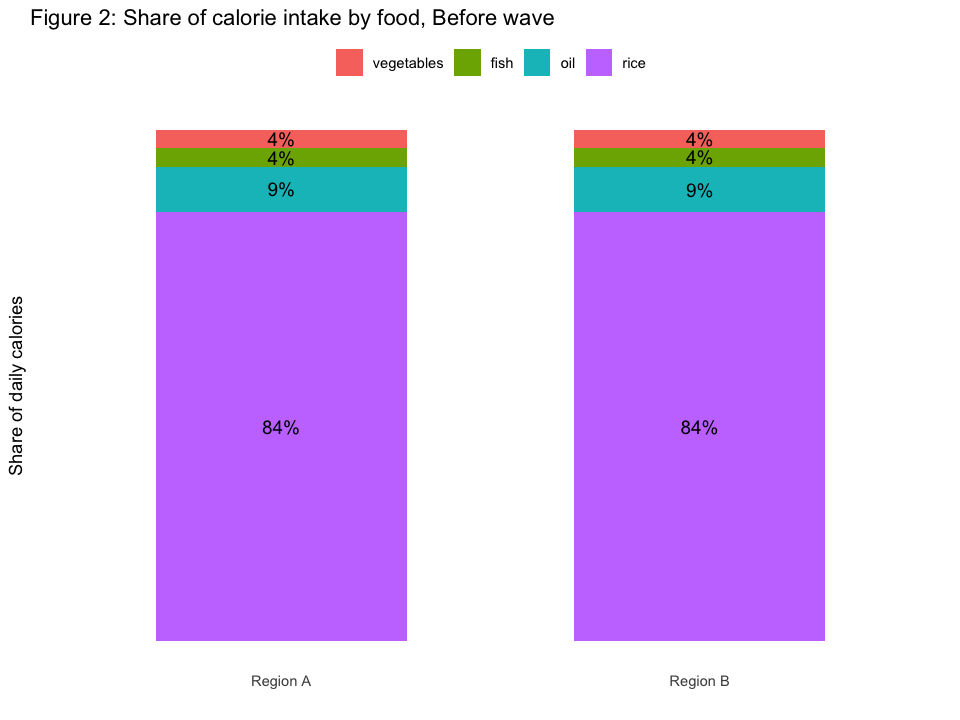

In [107]:
options(repr.plot.width = 8, repr.plot.height = 6)

raw_data |>
  filter(wave == "Before") |>
  group_by(region, food) |>
  summarise(kcal = mean(food_caloric_intake), .groups = "drop") |>
  group_by(region) |>
  mutate(share = kcal / sum(kcal),
         region = paste("Region", region)) |>
  ungroup() |>
  mutate(food = fct_reorder(food, share)) |>
  ggplot(aes(region, share, fill = food)) +
  geom_col(width = 0.6) +
  geom_text(aes(label = scales::percent(share, accuracy = 1)),
            position = position_stack(vjust = 0.5), size = 4) +
  #scale_y_continuous(labels = scales::percent(share, accuracy = 1)) +
  labs(title = "Figure 2: Share of calorie intake by food, Before wave",
       x = NULL, y = "Share of daily calories", fill = NULL,
       caption = "") +
  theme_minimal() +
  theme(legend.position = "top",
        panel.grid = element_blank(),
        axis.text.y = element_blank())

Rice is by far the cheapest source of calories: one currency unit buys 1,500 kcal of rice, compared with 150 kcal of vegetables and only 100 kcal of fish, the most expensive source (Table 2). One unit spent on rice therefore provides 15 times as many calories as one unit spent on fish. As a result, a household that shifts spending from rice to fish lowers the calories it obtains per unit spent, and its total calorie intake can fall even when its food spending stays constant or rises. This raises a key question for the evaluation: if the subsidy frees resources, do households spend them on more rice or on more expensive foods such as fish?

In [ ]:
cost <- raw_data |>
  filter(wave == "Before") |>
  group_by(food) |>
  summarise(price_kg = mean(price_g) * 1000,
            kcal_g   = mean(kcal_per_g),
            .groups = "drop") |>
  mutate(kcal_per_unit = kcal_g * 1000 / price_kg) |>
  arrange(desc(kcal_per_unit))

tbl3 <- cost |>
  gt(rowname_col = "food") |>
  tab_header(title = "Table 2: Cost of calories by food, Before wave") |>
  cols_label(price_kg = "Price per kg", kcal_g = "kcal per gram", kcal_per_unit = "kcal per currency unit") |>
  fmt_number(columns = c(price_kg, kcal_g), decimals = 2) |>
  fmt_number(columns = kcal_per_unit, decimals = 0) |>
  cols_align(align = "center") |>
  tab_source_note("kcal per currency unit = kcal per gram × 1,000 / price per kg. Under the subsidy, rice costs 2.4 × 0.75 = 1.8 per kg for treated households.")

IRdisplay::display_html(as_raw_html(tbl3))

"kcal per currency unit = kcal per gram × 1,000 / price per kg. Under the subsidy, rice costs 2.4 × 0.75 = 1.8 per kg for treated households."


Figure 2 relates baseline resources to rice and fish consumption in the Before wave, to check whether richer households eat less rice and more fish. The data show no such pattern: none of the slopes is statistically significant, in the full sample or within either region. In the full sample, one additional currency unit of resources is associated with 0.61 g less rice and 0.2 g more fish per person per day. The regions differ in sign: in region A, rice and fish consumption fall slightly with resources (−1.27 g and −0.08 g), while in region B both rise slightly (0.06 g and 0.51 g). These magnitudes are also small in practical terms: across the full range of resources, about 6 units, the largest slope implies a change of 6 × 1.27 ≈ 8 g of rice, less than 2% of average consumption. The cross-section therefore offers no evidence that rice behaves as an inferior good, and any explanation of the subsidy's effect needs to rest on the experimental comparison rather than on differences between households.

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


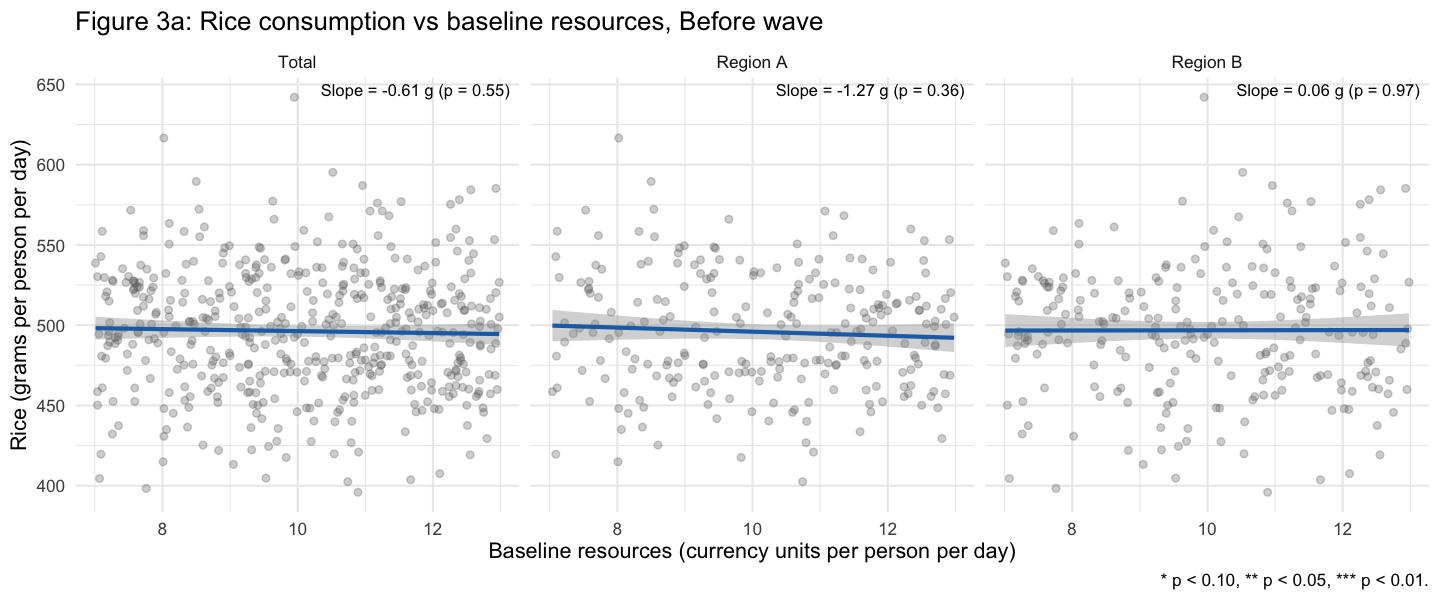

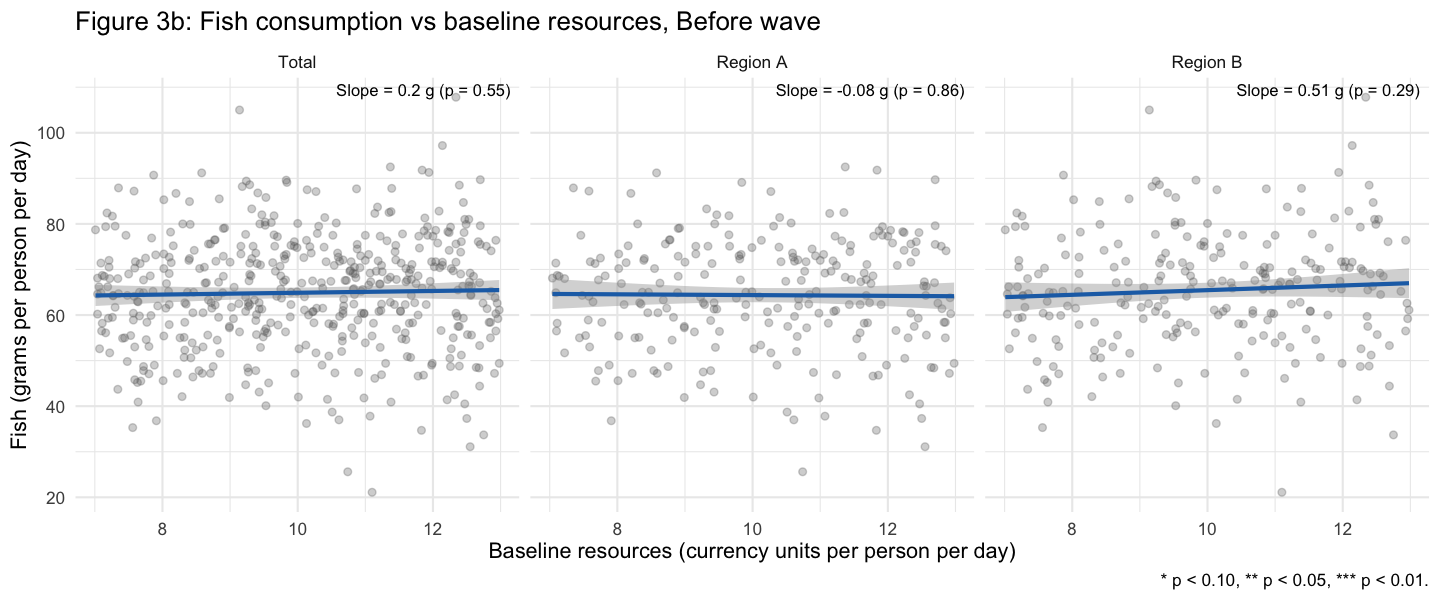

In [108]:
options(repr.plot.width = 12, repr.plot.height = 5)

engel_data <- raw_data |>
  filter(wave == "Before", food %in% c("rice", "fish")) |>
  mutate(region = paste("Region", region))

engel_data <- bind_rows(engel_data,
                        mutate(engel_data, region = "Total")) |>
  mutate(region = factor(region, levels = c("Total", "Region A", "Region B")))

slopes <- engel_data |>
  group_by(region, food) |>
  summarise(slope = coef(lm(grams_consumed ~ baseline_resources))[2],
            p     = summary(lm(grams_consumed ~ baseline_resources))$coefficients[2, 4],
            .groups = "drop") |>
  mutate(stars = case_when(p < 0.01 ~ "***",
                           p < 0.05 ~ "**",
                           p < 0.10 ~ "*",
                           TRUE     ~ ""),
         label = paste0("Slope = ", round(slope, 2), " g", stars, " (p = ", round(p, 2), ")"))

# Rice
ggplot(filter(engel_data, food == "rice"), aes(baseline_resources, grams_consumed)) +
  geom_point(alpha = 0.3, colour = "grey40") +
  geom_smooth(method = "lm", colour = "#1f6fb4") +
  geom_text(data = filter(slopes, food == "rice"),
            aes(x = Inf, y = Inf, label = label),
            hjust = 1.05, vjust = 1.5, size = 3.5) +
  facet_wrap(~ region) +
  labs(title = "Figure 3a: Rice consumption vs baseline resources, Before wave",
       x = "Baseline resources (currency units per person per day)",
       y = "Rice (grams per person per day)",
       caption = "* p < 0.10, ** p < 0.05, *** p < 0.01.") +
  theme_minimal(base_size = 13)

# Fish
ggplot(filter(engel_data, food == "fish"), aes(baseline_resources, grams_consumed)) +
  geom_point(alpha = 0.3, colour = "grey40") +
  geom_smooth(method = "lm", colour = "#1f6fb4") +
  geom_text(data = filter(slopes, food == "fish"),
            aes(x = Inf, y = Inf, label = label),
            hjust = 1.05, vjust = 1.5, size = 3.5) +
  facet_wrap(~ region) +
  labs(title = "Figure 3b: Fish consumption vs baseline resources, Before wave",
       x = "Baseline resources (currency units per person per day)",
       y = "Fish (grams per person per day)",
       caption = "* p < 0.10, ** p < 0.05, *** p < 0.01.") +
  theme_minimal(base_size = 13)

## Question 3: Design a credible evaluation
*What comparison would allow you to assess whether the subsidy achieved its objective? Describe the outcome you will evaluate, the counterfactual you need and how the available data can help you approximate it. Explain why your comparison is informative about the policy rather than simply about differences between households or changes over time. State the assumptions your interpretation requires. Choose the tables or plots that would make your evaluation convincing to someone who has not seen the data.*

[MR comment]: I suggest we do a DiD (difference-in-differences) as our empirical strategy to compare changes in caloric intakes for treatment and control groups during and after. DiDs are good because the method exploits some naturally occurring events that change the treatment status of some units over time.

Necessary ingredients:
• Need an event that affects only a sub-population
• Observe the outcome of interest before and after the treatment
• Observe the outcome of interest for both treated and untreated groups

[MR comment]: I had a bit of help from old uni notes + LLM to put the equation together - the only part I'm not confident about is the choice of fixed effects to be region x time

[JE comment]: yes, it is correct since the randomization was made inside each region. So, by definition, it is not the same in A and B.

$$Y_{it} = \alpha_i + \lambda_{r(i)t} + \beta_D\,(T_i \times \text{During}_t) + \beta_A\,(T_i \times \text{After}_t) + \varepsilon_{it}$$

where:

- $Y_{it}$ is the **total** calorie intake of household $i$ in wave $t$, in kcal per person per day, summed over rice, fish, vegetables and oil.
- $\alpha_i$ is a household fixed effect, which absorbs every household characteristic that does not change across waves.
- $\lambda_{r(i)t}$ is a region $\times$ wave fixed effect, which absorbs shocks common to all households in a region in a given wave. Randomisation was done within region, so this matches the design.
- $T_i = 1$ if household $i$ was randomly assigned to the subsidy, and $0$ otherwise.
- $\text{During}_t$ and $\text{After}_t$ are wave indicators. The Before wave is the omitted reference.
- Standard errors are clustered by household, because each household is observed three times.

Including region and time period fixed effects allow our comparison to be informative about the policy because we are controlling for differences between households and changes over time.


DiD ssumptions required:
Unobservables that affect the outcome do not vary differently in time between treated and control units. Without the treatment, the outcome of the treated control units would have changed by the same amount. The potential outcome (y0) or (y1) of the treated and control units change by the same amount between periods 0 and 1 = the Parallel Trends Assumption (PTA).

The PTA translates to:

• Unobservables that affect the outcome in average do not vary differently in
time between treated and control units

• Without the treatment, the average outcome of the treated and control units
would have changed by the same amount

Parallel trends holds by design in expectation, because randomisation makes the two groups the same in every way apart from the subsidy. Table 1 is our evidence.

## Question 4: Assess the evidence
*Carry out your evaluation and report the direction and size of the estimated policy effect. How strong is the evidence for your conclusion? Address uncertainty in a way you can explain, taking account of how the observations were collected.*

*Decide whether a single overall result adequately describes the pilot. Investigate any differences in responses that you think matter for the policy decision, and justify your choices. Revisit your initial prediction: what did you learn, and what remains unresolved?*

Using consumption surveys gathered before, during, and after the subsidy was introduced, we find no evidence that the subsidy improved calorie intake for the pooled sample and infact might harm it --> we find decreased calorie intake, statistically significant treatment effect during. Considering the regions separately, we find that households in Region A especially reduce their intake of calories in response to the price subsidy. Effect goes away after subsidy ends.

In [111]:
# not 100% sure about this code - only done DiDs in stata so needed LLM
regression_data <- raw_data |>
  group_by(household_id, region, treated, wave) |>
  summarise(total_caloric_intake = sum(food_caloric_intake), .groups = "drop") |>
  mutate(wave = factor(wave, levels = c("Before", "During", "After")),
         wave_during = as.integer(wave == "During"),
         wave_after  = as.integer(wave == "After"))

nrow(regression_data)                         
mean(regression_data$total_caloric_intake) 

did <- feols(total_caloric_intake ~ treated:wave_during + treated:wave_after |
               household_id + region^wave,
             data = regression_data, cluster = ~household_id)
#summary(did)

library(modelsummary)

control_mean <- mean(regression_data$total_caloric_intake[regression_data$treated == 0 &
                                                            regression_data$wave == "Before"])

extra <- data.frame(term = "Control mean, Before",
                    `Calorie intake` = sprintf("%.1f", control_mean),
                    check.names = FALSE)

tbl4 <- modelsummary(list("Calorie intake" = did),
                     coef_map = c("treated:wave_during" = "Treated × During",
                                  "treated:wave_after"  = "Treated × After"),
                     stars    = c("*" = 0.10, "**" = 0.05, "***" = 0.01),
                     gof_map  = c("nobs", "r.squared", "r2.within"),
                     add_rows = extra,
                     output   = "gt") |>
  tab_header(title = "Table 4: Effect of the rice subsidy on calorie intake") |>
  tab_source_note("Dependent variable: calorie intake in kcal per person per day. Household and region × wave fixed effects. Standard errors clustered by household in parentheses.")

IRdisplay::display_html(as_raw_html(tbl4))



[1] 1440

[1] 2111.16

"* p < 0.1, ** p < 0.05, *** p < 0.01"
Dependent variable: calorie intake in kcal per person per day. Household and region × wave fixed effects. Standard errors clustered by household in parentheses.


In [ ]:
regression_data <- regression_data |>
  mutate(region_b = as.integer(region == "B"))

did_a <- feols(total_caloric_intake ~ treated:wave_during + treated:wave_after |
                 household_id + wave,
               data = filter(regression_data, region == "A"), cluster = ~household_id)

did_b <- feols(total_caloric_intake ~ treated:wave_during + treated:wave_after |
                 household_id + wave,
               data = filter(regression_data, region == "B"), cluster = ~household_id)

did_diff <- feols(total_caloric_intake ~ treated:wave_during + treated:wave_after +
                    treated:wave_during:region_b + treated:wave_after:region_b |
                    household_id + region^wave,
                  data = regression_data, cluster = ~household_id)

tbl5 <- modelsummary(list("Pooled" = did, "Region A" = did_a, "Region B" = did_b, "Difference" = did_diff),
                     coef_map = c("treated:wave_during"          = "Treated × During",
                                  "treated:wave_after"           = "Treated × After",
                                  "treated:wave_during:region_b" = "Treated × During × Region B",
                                  "treated:wave_after:region_b"  = "Treated × After × Region B"), # nolint
                     stars   = c("*" = 0.10, "**" = 0.05, "***" = 0.01),
                     gof_map = c("nobs", "r.squared"),
                     output  = "gt") |>
  tab_header(title = "Table 5: Effect of the rice subsidy on calorie intake, by region") |>
  tab_source_note("Dependent variable: calorie intake in kcal per person per day. Household fixed effects; wave fixed effects in the regional models and region × wave fixed effects in the pooled and difference models. Standard errors clustered by household in parentheses.")

IRdisplay::display_html(as_raw_html(tbl5))

"* p < 0.1, ** p < 0.05, *** p < 0.01"
Dependent variable: calorie intake in kcal per person per day. Household fixed effects; wave fixed effects in the regional models and region × wave fixed effects in the pooled and difference models. Standard errors clustered by household in parentheses.


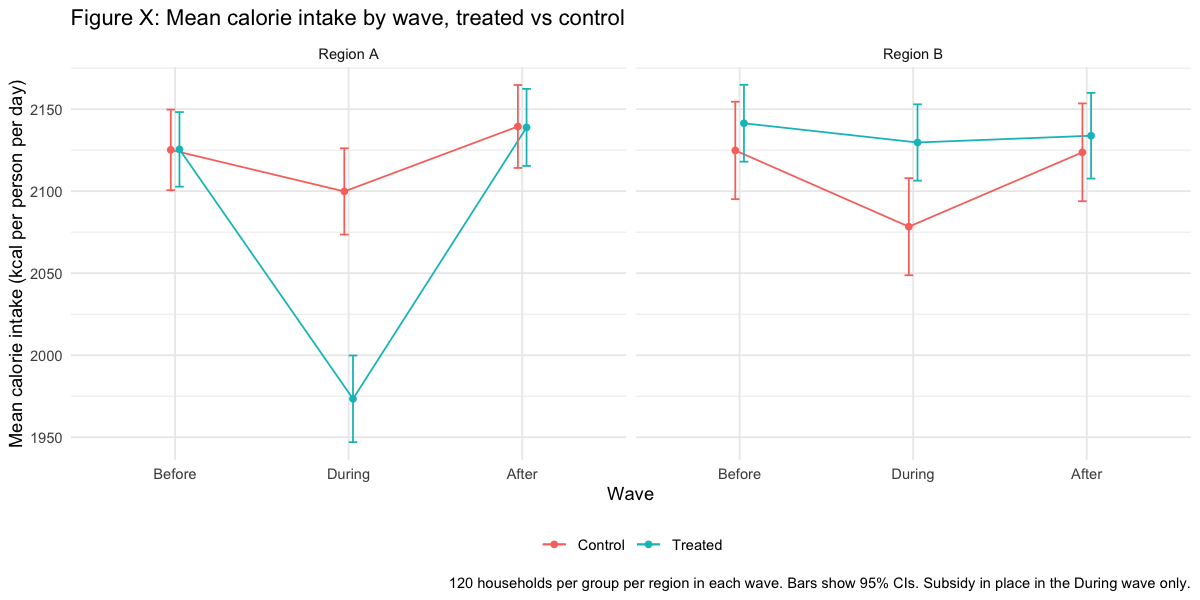

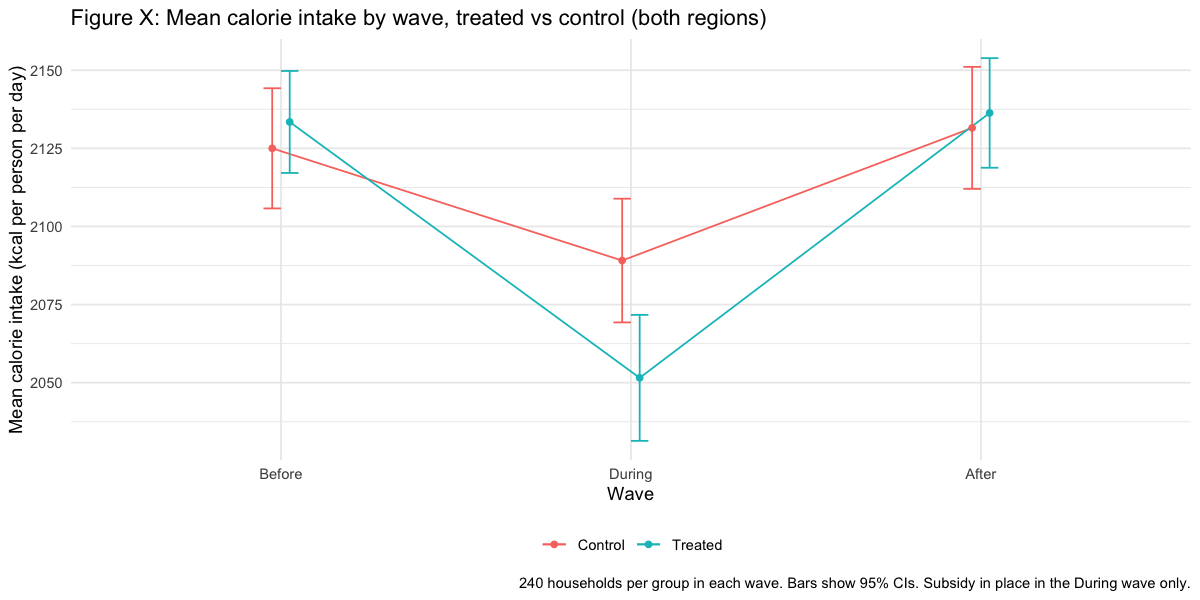

In [112]:
options(repr.plot.width = 10, repr.plot.height = 5)

regression_data |>
  mutate(wave  = factor(wave, levels = c("Before", "During", "After")),
         group = if_else(treated == 1, "Treated", "Control")) |>
  group_by(region, wave, group) |>
  summarise(mean_kcal = mean(total_caloric_intake),
            se = sd(total_caloric_intake) / sqrt(n()),
            n  = n(), .groups = "drop") |>
  ggplot(aes(wave, mean_kcal, colour = group, group = group)) +
  geom_line(position = position_dodge(0.1)) +
  geom_point(position = position_dodge(0.1)) +
  geom_errorbar(aes(ymin = mean_kcal - 1.96 * se, ymax = mean_kcal + 1.96 * se),
                width = 0.1, position = position_dodge(0.1)) +
  facet_wrap(~ region, labeller = labeller(region = c(A = "Region A", B = "Region B"))) +
  labs(title = "Figure X: Mean calorie intake by wave, treated vs control",
       x = "Wave", y = "Mean calorie intake (kcal per person per day)", colour = NULL,
       caption = "120 households per group per region in each wave. Bars show 95% CIs. Subsidy in place in the During wave only.") +
  theme_minimal() +
  theme(legend.position = "bottom")

  regression_data |>
  mutate(wave  = factor(wave, levels = c("Before", "During", "After")),
         group = if_else(treated == 1, "Treated", "Control")) |>
  group_by(wave, group) |>
  summarise(mean_kcal = mean(total_caloric_intake),
            se = sd(total_caloric_intake) / sqrt(n()),
            n  = n(), .groups = "drop") |>
  ggplot(aes(wave, mean_kcal, colour = group, group = group)) +
  geom_line(position = position_dodge(0.1)) +
  geom_point(position = position_dodge(0.1)) +
  geom_errorbar(aes(ymin = mean_kcal - 1.96 * se, ymax = mean_kcal + 1.96 * se),
                width = 0.1, position = position_dodge(0.1)) +
  labs(title = "Figure X: Mean calorie intake by wave, treated vs control (both regions)",
       x = "Wave", y = "Mean calorie intake (kcal per person per day)", colour = NULL,
       caption = "240 households per group in each wave. Bars show 95% CIs. Subsidy in place in the During wave only.") +
  theme_minimal() +
  theme(legend.position = "bottom")

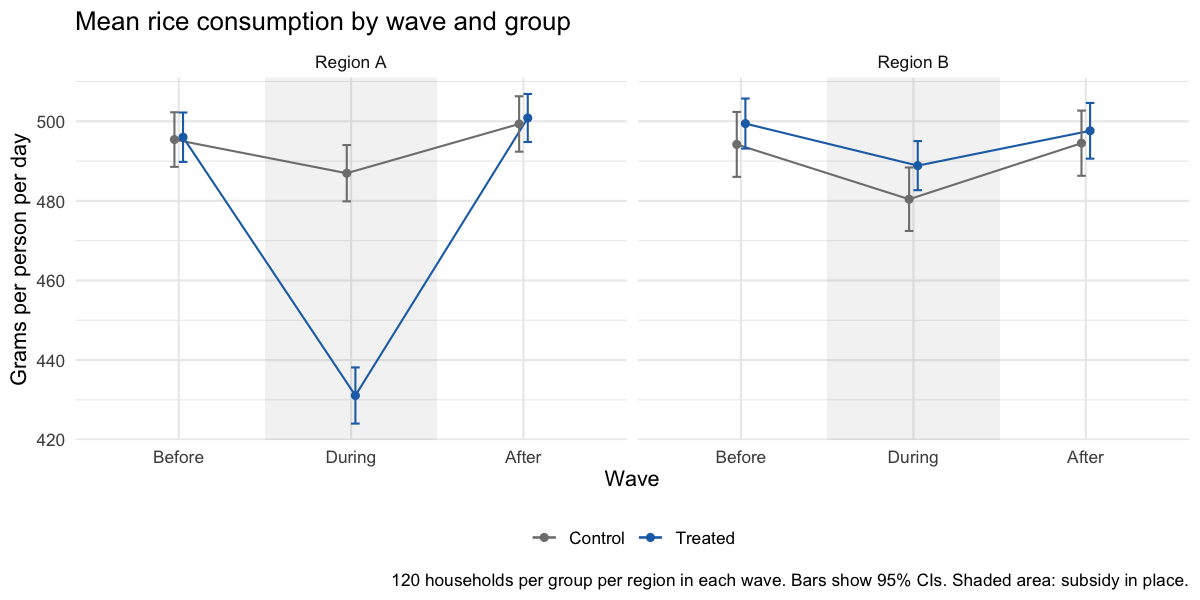

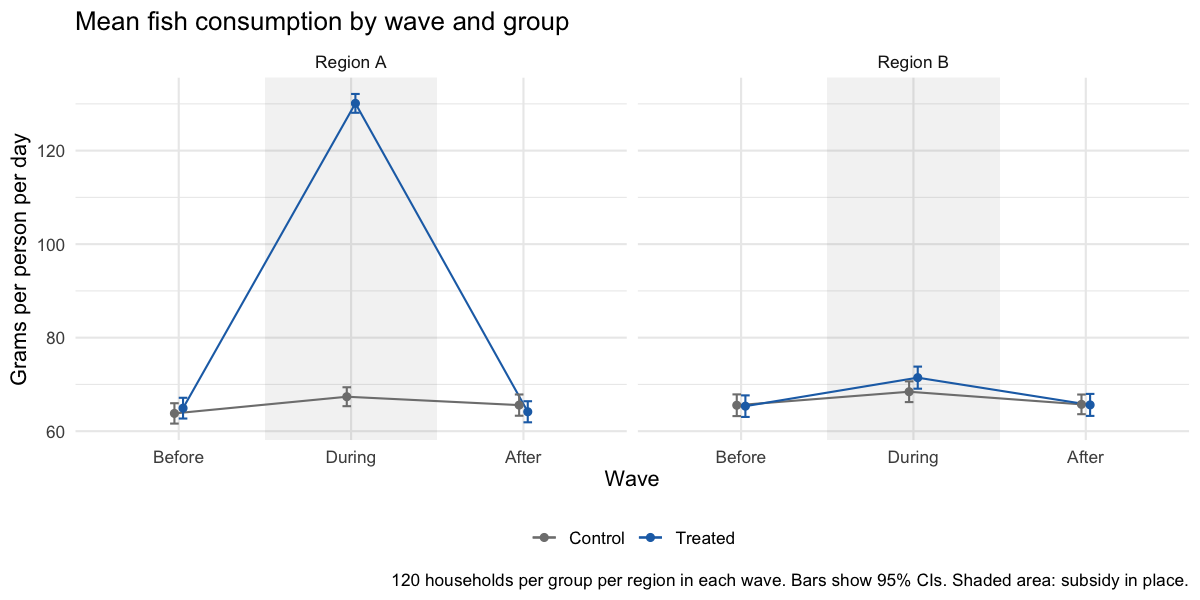

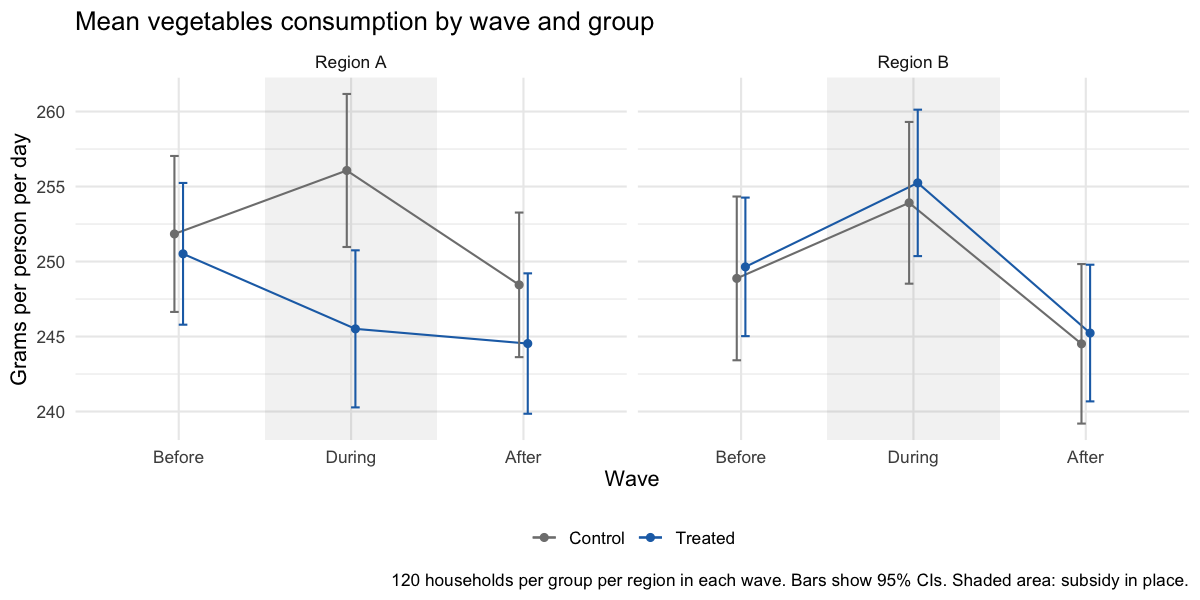

In [113]:
options(repr.plot.width = 10, repr.plot.height = 5)

dodge <- position_dodge(0.1)

food_means <- raw_data |>
  mutate(wave  = factor(wave, levels = c("Before", "During", "After")),
         group = if_else(treated == 1, "Treated", "Control"),
         region = paste("Region", region)) |>
  group_by(food, region, wave, group) |>
  summarise(mean = mean(grams_consumed),
            se = sd(grams_consumed) / sqrt(n()),
            .groups = "drop")

foods <- c("rice", "fish", "vegetables")

for (f in foods) {
  p <- ggplot(filter(food_means, food == f), aes(wave, mean, colour = group, group = group)) +
    annotate("rect", xmin = 1.5, xmax = 2.5, ymin = -Inf, ymax = Inf, alpha = 0.08) +
    geom_line(position = dodge) +
    geom_point(position = dodge) +
    geom_errorbar(aes(ymin = mean - 1.96 * se, ymax = mean + 1.96 * se),
                  width = 0.1, position = dodge) +
    facet_wrap(~ region) +
    scale_colour_manual(values = c(Control = "grey50", Treated = "#1f6fb4")) +
    labs(title = paste("Mean", f, "consumption by wave and group"),
         x = "Wave", y = "Grams per person per day", colour = NULL,
         caption = "120 households per group per region in each wave. Bars show 95% CIs. Shaded area: subsidy in place.") +
    theme_minimal(base_size = 13) +
    theme(legend.position = "bottom")

  print(p)
}

##### Question 5: Develop an economic explanation
*How could households’ choices generate the pattern you found? Develop an explanation using the standard consumer choice problem. Specify the relevant goods, the budget constraint and the assumptions about preferences that your argument needs.*

*Use a clearly labelled budget-line and indifference-curve diagram to explain how the price change affects the chosen bundle. Discuss the roles of the substitution and income effects, and whether your explanation requires any goods to be normal or inferior. Connect the logic to your empirical findings. You do not need to estimate a utility function.*

[Useful set up for the question] from the paper - we can edit some of the wording:
Consider a simplified depiction of an impoverished consumer near a subsistence level of nutrition, whose diet consists of only two foods: a basic or staple good like rice, wheat, or maize and a ‘‘fancy’’ good like meat. The basic good offers a high level of calories at low cost, while the fancy good is preferred because of its taste but provides few calories per unit of currency. The poorest consumers will eat a lot of the staple in order to get enough calories and other nutrients to meet their basic needs, and they will use whatever money they have left over to purchase meat. As a result, consumers spend a high fraction of their budget on, and receive most of their nutrition from, the staple. By lowering the cost of the staple, subsidies free up substantial funds to be spent in other ways, that is, they induce large wealth effects. As households respond by substituting toward the types of goods that wealthier households consume, they may switch away from these nutritious staples, which are typically strongly inferior goods, and toward foods such as meat that offer more taste or add variety to the diet but are more costly sources of nutrients,2 or toward nonfood items. More generally, if consumers value the nonnutritional attributes of foods in addition to the nutritional attributes, the net nutritional consequences of a subsidy will depend on how consumers substitute among foods (as well as between food and nonfood items). If this substitution toward less nutritive foods is substantial enough, consumers may weaken or potentially even reverse the intended nutritional impact of the subsidies.

##### Question 6: Look for evidence of the mechanism
*Turn your explanation into predictions that you can investigate in the data. What patterns would strengthen it? What would cast doubt on it? Design and present the tables, plots or other comparisons that you judge most informative, and explain what each one establishes.*

*Consider at least one plausible alternative explanation and assess how far the available evidence distinguishes between the two. Be precise about the difference between describing a pattern and establishing why households chose it. Revise your explanation if your evidence calls for it, and identify any additional information you would need.*

[Helpful info from the paper]:
However, subsidizing goods on which households spend a high proportion of their budget can create large wealth effects. Consumers may then substitute toward foods with higher nonnutritional attributes (such as taste) but lower nutritional content per unit of currency, weakening or perhaps even reversing the subsidy’s intended impact.

##### Question 7: Brief the policymaker
*Write a 200–300 word briefing answering the government’s question: should it expand, revise or discontinue the programme? Ground your recommendation in your evidence and explain the main mechanism in plain language.*

*Does your verdict on the policy’s stated objective also determine whether households are better orworse off? Explain. Identify the most useful additional evidence or policy test before a final decision, and be clear about the limits of what this pilot establishes.*